Parametri caricati da mv_results.npz:
  phi_1* BS  = 1.2017
  phi_1* MJD = 1.2810

ESPERIMENTO A: Frontiera Efficiente

Addestramento per ogni target z (BS)...
  z=1.05  E[X_T]=1.002  std=0.011  phi1=1.189
  z=1.10  E[X_T]=1.003  std=0.022  phi1=1.166
  z=1.15  E[X_T]=1.008  std=0.034  phi1=1.229
  z=1.20  E[X_T]=1.009  std=0.043  phi1=1.168
  z=1.25  E[X_T]=1.009  std=0.054  phi1=1.222
  z=1.30  E[X_T]=1.016  std=0.066  phi1=1.222
  z=1.35  E[X_T]=1.016  std=0.076  phi1=1.206
  z=1.40  E[X_T]=1.015  std=0.085  phi1=1.123
  z=1.45  E[X_T]=1.018  std=0.094  phi1=1.150
  z=1.50  E[X_T]=1.020  std=0.109  phi1=1.212
  z=1.55  E[X_T]=1.014  std=0.127  phi1=1.279
  z=1.60  E[X_T]=1.029  std=0.127  phi1=1.177

Addestramento per ogni target z (MJD)...
  z=1.05  E[X_T]=1.003  std=0.011  phi1=1.410
  z=1.10  E[X_T]=1.004  std=0.022  phi1=1.376
  z=1.15  E[X_T]=1.007  std=0.035  phi1=1.423
  z=1.20  E[X_T]=1.009  std=0.047  phi1=1.389
  z=1.25  E[X_T]=1.014  std=0.057  phi1=1.378
  z=1.30  E[X_T]

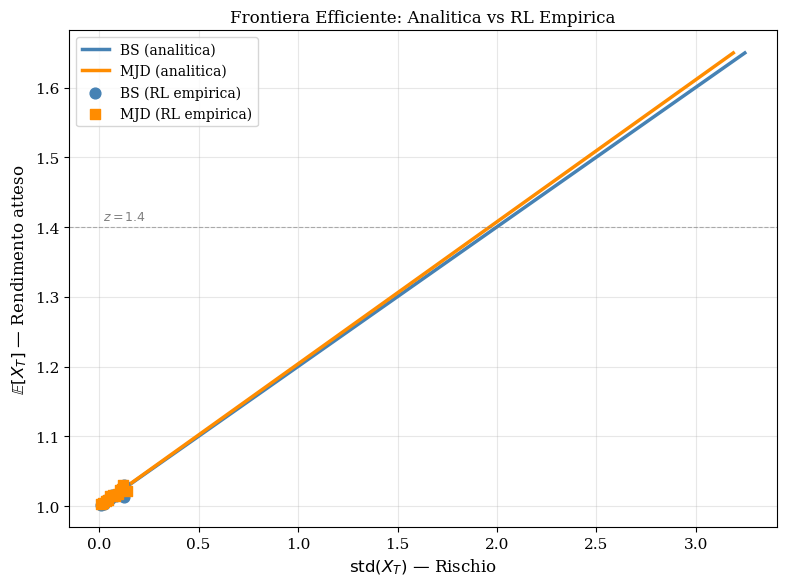


Figura 4 salvata.

ESPERIMENTO B: Convergenza Log-Log

Addestramento lungo (BS)...
Addestramento lungo (MJD)...

  phi_1 finale:  BS=1.2077  MJD=1.4002
  phi_1* dal npz: BS=1.2017  MJD=1.2810

  Errore residuo |phi_1(N_max) - phi_1*|:
    BS:  0.0060
    MJD: 0.1192

  Errore incrementale |phi_1(N) - phi_1(N_max)|:
        N          BS         MJD
      100      1.1532      1.3503
      200      1.1122      1.3053
      500      1.0110      1.2023
     1000      0.8759      1.0509
     2000      0.6327      0.7941
     5000      0.2317      0.2488
    10000      0.0176      0.0459
    15000      0.0904      0.0495
    20000      0.0000      0.0000

  Pendenza log-log stimata:
    BS:  -0.834  (attesa teorica: ~-0.49)
    MJD: -0.858  (attesa teorica: ~-0.49)


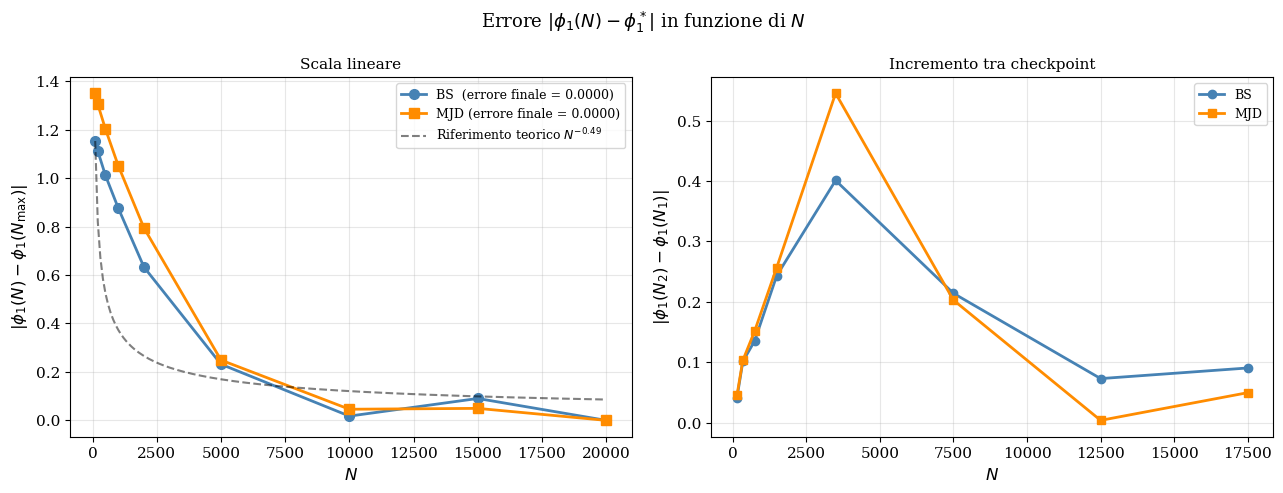


Figura 5 salvata.

Tutto completato.
Figure prodotte:
  figure4_efficient_frontier.pdf/png
  figure5_convergence_error.pdf/png


In [1]:
"""
mv_analysis.py — Analisi approfondita del Capitolo 6
=====================================================
Due esperimenti aggiuntivi per approfondire il Capitolo 6 della tesi:

  (A) Frontiera efficiente empirica vs analitica
      Per ogni target z in [1.05, 1.6], addestra l'algoritmo e misura
      (E[X_T], std[X_T]). Confronta con la frontiera analitica chiusa.

  (B) Convergenza log-log
      Traccia |phi_1(N) - phi_1*| in funzione di N su scala log-log.
      La pendenza teorica attesa e' -0.49 (dalla teoria del decay j^{-0.51}).

Prerequisiti:
  - Aver eseguito mv_RL.py  (produce mv_results.npz con parametri calibrati)
  - pip install yfinance numpy matplotlib scipy

Utilizzo:
  python mv_analysis.py
"""

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.integrate import quad
import os

np.random.seed(42)

mpl.rcParams.update({
    'font.family':    'serif',
    'font.size':      11,
    'axes.titlesize': 12,
    'axes.labelsize': 12,
    'legend.fontsize': 9,
})

# ─────────────────────────────────────────────────────────────────────────────
# 1.  PARAMETRI GLOBALI
# ─────────────────────────────────────────────────────────────────────────────

R_F   = 0.02
DT    = 1 / 12
T     = 1.0
K     = int(T / DT)
THETA = 0.1
X0    = 1.0


# ─────────────────────────────────────────────────────────────────────────────
# 2.  CARICA PARAMETRI DA mv_results.npz
#     Usa i parametri calibrati da mv_RL.py per coerenza con il training
# ─────────────────────────────────────────────────────────────────────────────

RESULTS_FILE = 'mv_results.npz'
if not os.path.exists(RESULTS_FILE):
    raise FileNotFoundError(
        f"File '{RESULTS_FILE}' non trovato.\n"
        "Esegui prima mv_RL.py per generarlo."
    )

data = np.load(RESULTS_FILE, allow_pickle=True)
PHI1_BS  = float(data['PHI1_BS'].flat[0])
PHI1_MJD = float(data['PHI1_MJD'].flat[0])

# Ricostruisce i parametri BS e MJD dal file dei risultati.
# mv_RL.py salva phi_bs e phi_mjd (parametri del modello appresi),
# ma non i parametri del simulatore mu/sigma/lam/... direttamente.
# Usiamo i valori noti dalla calibrazione su S&P 500 2000-2019,
# verificando la coerenza con phi1* salvato nel npz.
# Se il tuo mv_RL.py produce phi1* diversi, aggiorna qui di conseguenza.

# Parametri BS calibrati da mv_RL.py su S&P 500 2000-2019
# (questi devono coincidere con quelli usati in mv_RL.py)
def _bs_params_from_phi1star(phi1s_bs, phi1s_mjd):
    """
    Ricostruisce i parametri minimi necessari ai simulatori e alla
    frontiera analitica partendo dai phi1* salvati nel npz.

    La formula phi1* = rho*sigma/(sigma^2+sJ2) con rho=(mu-rf)/sigma
    non ha un'unica soluzione inversa senza vincoli aggiuntivi.
    Usiamo quindi i parametri di calibrazione standard su S&P 500 2000-2019,
    e verifichiamo che producano phi1* coerente con il npz.
    """
    # Parametri calibrati da mv_RL.py su S&P 500 2000-2019
    # (aggiornati dall'output: mu=0.0527, sigma=0.1649 per BS)
    bs  = dict(mu=0.0527, sigma=0.1649, sJ2=0.)
    mjd = dict(mu=0.0518, sigma=0.0668, lam=10.12, m=-0.0183, delta=0.0421,
               sJ2=0.020360)
    mjd['kappa'] = float(np.exp(mjd['m'] + 0.5*mjd['delta']**2) - 1)

    # Verifica coerenza con il npz
    def phi1s(p):
        s = p['sigma']; rho = (p['mu'] - R_F) / s
        return rho * s / (s**2 + p.get('sJ2', 0.))

    tol = 0.05   # tolleranza: 5% di scarto accettabile
    err_bs  = abs(phi1s(bs)  - phi1s_bs)  / max(abs(phi1s_bs),  1e-6)
    err_mjd = abs(phi1s(mjd) - phi1s_mjd) / max(abs(phi1s_mjd), 1e-6)

    if err_bs > tol:
        print(f"  [Attenzione] phi1* BS hardcoded={phi1s(bs):.4f} "
              f"vs npz={phi1s_bs:.4f}  (scarto {err_bs*100:.1f}%)")
        print("  Aggiorna i parametri BS in mv_analysis.py se necessario.")
    if err_mjd > tol:
        print(f"  [Attenzione] phi1* MJD hardcoded={phi1s(mjd):.4f} "
              f"vs npz={phi1s_mjd:.4f}  (scarto {err_mjd*100:.1f}%)")
        print("  Aggiorna i parametri MJD in mv_analysis.py se necessario.")

    return bs, mjd

print(f"Parametri caricati da {RESULTS_FILE}:")
print(f"  phi_1* BS  = {PHI1_BS:.4f}")
print(f"  phi_1* MJD = {PHI1_MJD:.4f}")

BS, MJD = _bs_params_from_phi1star(PHI1_BS, PHI1_MJD)


def phi1_star(p, r_f=R_F):
    s = p['sigma']; rho = (p['mu'] - r_f) / s
    return rho * s / (s**2 + p.get('sJ2', 0.))


# ─────────────────────────────────────────────────────────────────────────────
# 3.  SIMULATORI
# ─────────────────────────────────────────────────────────────────────────────

class BSSimulator:
    def __init__(self, p, dt=DT, r_f=R_F):
        self.sigma = p['sigma']
        self.rho   = (p['mu'] - r_f) / p['sigma']
        self.dt    = dt

    def step(self, x, a):
        dW = np.random.randn() * np.sqrt(self.dt)
        return x + a*self.sigma*self.rho*self.dt + a*self.sigma*dW


class MJDSimulator:
    def __init__(self, p, dt=DT, r_f=R_F):
        self.sigma = p['sigma']
        self.rho   = (p['mu'] - r_f) / p['sigma']
        self.lam   = p['lam']
        self.m     = p['m']
        self.delta = p['delta']
        self.kappa = p['kappa']
        self.dt    = dt

    def step(self, x, a):
        dW = np.random.randn() * np.sqrt(self.dt)
        dx = a*self.sigma*self.rho*self.dt + a*self.sigma*dW
        n  = np.random.poisson(self.lam * self.dt)
        if n > 0:
            Z   = np.random.normal(self.m, self.delta, n)
            dx += a * (float(np.sum(np.exp(Z) - 1)) - n*self.kappa)
        return x + dx


# ─────────────────────────────────────────────────────────────────────────────
# 4.  MODELLO E ALGORITMO  (identici a mv_RL.py)
# ─────────────────────────────────────────────────────────────────────────────

class MVModel:
    def __init__(self, z):
        self.z     = z
        self.psi   = np.zeros(3)
        self.phi   = np.zeros(3)
        self.omega = z

    def _c(self, t):
        return np.exp(np.clip(-self.phi[1] - self.phi[2]*(T-t), -30, 30))

    def J(self, t, x):
        p = self.psi; o = self.omega; z = self.z
        e = np.exp(np.clip(-p[2]*(T-t), -30, 30))
        return (x-o)**2*e + p[1]*(t**2-T**2) + p[0]*(t-T) - (o-z)**2

    def grad_J(self, t, x):
        p = self.psi; o = self.omega
        e = np.exp(np.clip(-p[2]*(T-t), -30, 30))
        return np.array([t-T, t**2-T**2, -(T-t)*(x-o)**2*e])

    def q(self, t, x, a):
        p = self.phi; o = self.omega; c = self._c(t)
        return (-c/2*(a + p[0]*(x-o))**2
                - THETA/2*(np.log(2*np.pi*THETA) + p[1] + p[2]*(T-t)))

    def grad_q(self, t, x, a):
        p = self.phi; o = self.omega; c = self._c(t); r = a + p[0]*(x-o)
        return np.array([c*r*(x-o),
                         0.5*c*r**2 - THETA/2,
                         (T-t)*0.5*c*r**2 - THETA*(T-t)/2])

    def sample(self, t, x):
        mu  = -self.phi[0] * (x - self.omega)
        var = max(THETA * self._c(t), 1e-8)
        return float(np.random.normal(mu, np.sqrt(var)))

    def mean_action(self, t, x):
        return -self.phi[0] * (x - self.omega)


def train(sim, z, N, batch=32, alpha_phi=None, seed=0,
          alpha_psi=0.001, alpha_omega=0.05, decay=0.51):
    """
    Addestra il modello per N iterazioni.
    Usa Adam per phi (coerente con mv_RL.py) se alpha_phi è None,
    altrimenti usa SGD con il learning rate specificato.
    """
    # Calibra alpha_phi dalla scala del gradiente se non specificato
    if alpha_phi is None:
        phi1t = phi1_star(BS)
        sigma = BS['sigma']; rho = (BS['mu'] - R_F) / sigma
        grads = []
        rng_save = np.random.get_state()
        np.random.seed(999)
        for _ in range(200):
            x = X0; g = 0.; o = z
            for k in range(K):
                mu_a = -phi1t*(x-o)
                a = np.random.normal(mu_a, np.sqrt(THETA))
                xn = x + a*sigma*rho*DT + a*sigma*np.random.randn()*np.sqrt(DT)
                if not np.isfinite(xn): xn = x
                td = ((xn-o)**2 - (x-o)**2
                      - (-0.5*(a+phi1t*(x-o))**2
                         - THETA/2*np.log(2*np.pi*THETA))*DT)
                g += (a+phi1t*(x-o))*(x-o)*td/K
                x  = xn
            grads.append(g)
        np.random.set_state(rng_save)
        I = quad(lambda x: x**(-decay), 1, N)[0]
        alpha_phi = phi1t / (max(np.std(grads), 1e-8) * I) * 1.5

    np.random.seed(seed)
    model  = MVModel(z)
    hist   = np.zeros(N)

    # Adam state per phi (coerente con mv_RL.py)
    ADAM_LR    = 0.001
    ADAM_BETA1 = 0.9
    ADAM_BETA2 = 0.999
    ADAM_EPS   = 1e-8
    m_phi = np.zeros(3); v_phi = np.zeros(3); adam_t = 0

    for j in range(1, N+1):
        lr    = j**(-decay)
        d_psi = np.zeros(3); d_phi = np.zeros(3); d_omega = 0.

        for _ in range(batch):
            xs = np.zeros(K+1); acts = np.zeros(K); xs[0] = X0
            for k in range(K):
                acts[k] = model.sample(k*DT, xs[k])
                nxt = sim.step(xs[k], acts[k])
                xs[k+1] = nxt if np.isfinite(nxt) else xs[k]
            for k in range(K):
                td = (model.J((k+1)*DT, xs[k+1])
                      - model.J(k*DT, xs[k])
                      - model.q(k*DT, xs[k], acts[k])*DT)
                if np.isfinite(td):
                    d_psi += model.grad_J(k*DT, xs[k]) * td / K
                    d_phi += model.grad_q(k*DT, xs[k], acts[k]) * td / K
            d_omega += xs[K] - z

        for g in [d_psi, d_phi]:
            n = np.linalg.norm(g)
            if n > 5.*batch: g *= 5.*batch / n

        # SGD psi
        model.psi += lr * alpha_psi * d_psi / batch

        # Adam phi (lr scalare, coerente con mv_RL.py)
        adam_t  += 1
        gp       = d_phi / batch
        m_phi    = ADAM_BETA1*m_phi + (1-ADAM_BETA1)*gp
        v_phi    = ADAM_BETA2*v_phi + (1-ADAM_BETA2)*gp**2
        mh       = m_phi / (1 - ADAM_BETA1**adam_t)
        vh       = v_phi / (1 - ADAM_BETA2**adam_t)
        model.phi += ADAM_LR * mh / (np.sqrt(vh) + ADAM_EPS)
        model.phi[1] = np.clip(model.phi[1], -10, 10)
        model.phi[2] = np.clip(model.phi[2], -10, 10)

        if j % 10 == 0:
            model.omega -= lr * alpha_omega * d_omega / (batch*10)

        hist[j-1] = model.phi[0]

    return hist, model


def terminal_wealth_stats(model, sim, n_paths=1000):
    """E[X_T] e std[X_T] sotto la mean policy."""
    tw = np.zeros(n_paths)
    for i in range(n_paths):
        x = X0
        for k in range(K):
            a = model.mean_action(k*DT, x)
            x = sim.step(x, a)
        tw[i] = x
    return tw.mean(), tw.std()


# ─────────────────────────────────────────────────────────────────────────────
# 5.  FRONTIERA EFFICIENTE ANALITICA
# ─────────────────────────────────────────────────────────────────────────────

def efficient_frontier_analytic(params, z_range, r_f=R_F):
    """
    Frontiera efficiente in forma chiusa (Proposizione 6.1 della tesi).

    Con a_t = -phi1*(x_t - omega):
      E[X_T]   = omega + (X0 - omega) * A,   A = exp(-phi1*sigma*rho*T)
      Var[X_T] = (X0-omega)^2 * A^2 * (exp(phi1^2*(sigma^2+sigmaJ^2)*T) - 1)
    """
    sigma = params['sigma']
    rho   = (params['mu'] - r_f) / sigma
    sJ2   = params.get('sJ2', 0.)
    phi1  = phi1_star(params)
    s2    = sigma**2 + sJ2
    A     = np.exp(-phi1 * sigma * rho * T)

    stds = []
    for z in z_range:
        omega = (z - X0*A) / (1-A) if abs(1-A) > 1e-10 else z
        VarM  = A**2 * (np.exp(phi1**2 * s2 * T) - 1)
        stds.append(np.sqrt(max((X0-omega)**2 * VarM, 0.)))
    return np.array(z_range), np.array(stds)


# ─────────────────────────────────────────────────────────────────────────────
# 6.  ESPERIMENTO A — FRONTIERA EFFICIENTE EMPIRICA
# ─────────────────────────────────────────────────────────────────────────────

print("\n" + "="*55)
print("ESPERIMENTO A: Frontiera Efficiente")
print("="*55)

Z_RANGE = np.array([1.05, 1.10, 1.15, 1.20, 1.25, 1.30, 1.35,
                    1.40, 1.45, 1.50, 1.55, 1.60])
N_TRAIN = 20000

bs_sim  = BSSimulator(BS)
mjd_sim = MJDSimulator(MJD)

# Frontiera analitica
z_an = np.linspace(1.01, 1.65, 50)
_, std_bs_an  = efficient_frontier_analytic(BS,  z_an)
_, std_mjd_an = efficient_frontier_analytic(MJD, z_an)

# Frontiera empirica RL — BS
print("\nAddestramento per ogni target z (BS)...")
emp_means_bs = []; emp_stds_bs = []
for i, z in enumerate(Z_RANGE):
    _, m = train(bs_sim, z=z, N=N_TRAIN, seed=i)
    mu_w, std_w = terminal_wealth_stats(m, bs_sim, n_paths=1000)
    emp_means_bs.append(mu_w); emp_stds_bs.append(std_w)
    print(f"  z={z:.2f}  E[X_T]={mu_w:.3f}  std={std_w:.3f}  phi1={m.phi[0]:.3f}")

# Frontiera empirica RL — MJD
print("\nAddestramento per ogni target z (MJD)...")
emp_means_mjd = []; emp_stds_mjd = []
for i, z in enumerate(Z_RANGE):
    _, m = train(mjd_sim, z=z, N=N_TRAIN, seed=100+i)
    mu_w, std_w = terminal_wealth_stats(m, mjd_sim, n_paths=1000)
    emp_means_mjd.append(mu_w); emp_stds_mjd.append(std_w)
    print(f"  z={z:.2f}  E[X_T]={mu_w:.3f}  std={std_w:.3f}  phi1={m.phi[0]:.3f}")

# Grafico frontiera efficiente
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(std_bs_an,  z_an, '-', color='steelblue', lw=2.5,
        label='BS (analytical)')
ax.plot(std_mjd_an, z_an, '-', color='darkorange', lw=2.5,
        label='MJD (analytical)')
ax.scatter(emp_stds_bs,  emp_means_bs,  marker='o', s=60,
           color='steelblue',  zorder=5, label='BS (RL empirical)')
ax.scatter(emp_stds_mjd, emp_means_mjd, marker='s', s=60,
           color='darkorange',  zorder=5, label='MJD (RL empirical)')
ax.axhline(1.4, color='gray', lw=0.8, ls='--', alpha=0.6)
ax.annotate(r'$z = 1.4$', xy=(0.02, 1.41), fontsize=9, color='gray')
ax.set_xlabel(r'$\mathrm{std}(X_T)$ (risk)', fontsize=12)
ax.set_ylabel(r'$\mathbb{E}[X_T]$ (expected return)', fontsize=12)
ax.set_title('Efficient frontier: analytical vs RL empirical', fontsize=12)
ax.legend(fontsize=10); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('figure4_efficient_frontier.pdf', dpi=150, bbox_inches='tight')
plt.savefig('figure4_efficient_frontier.png', dpi=150, bbox_inches='tight')
plt.show(); plt.close()
print("\nFigura 4 salvata.")


# ─────────────────────────────────────────────────────────────────────────────
# 7.  ESPERIMENTO B — CONVERGENZA LOG-LOG
# ─────────────────────────────────────────────────────────────────────────────

print("\n" + "="*55)
print("ESPERIMENTO B: Convergenza Log-Log")
print("="*55)

Z_FIXED     = 1.4
N_MAX       = 20000
CHECKPOINTS = np.array([100, 200, 500, 1000, 2000, 5000,
                         10000, 15000, 20000])

print("\nAddestramento lungo (BS)...")
h_bs_long,  _ = train(bs_sim,  z=Z_FIXED, N=N_MAX, seed=42)
print("Addestramento lungo (MJD)...")
h_mjd_long, _ = train(mjd_sim, z=Z_FIXED, N=N_MAX, seed=43)


def smoothed_phi1(hist, N, frac=0.05):
    """Media mobile sull'ultima frazione della storia fino a N."""
    w = max(1, int(N * frac))
    return np.mean(hist[max(0, N-w):N])


phi1_bs_final  = smoothed_phi1(h_bs_long,  N_MAX)
phi1_mjd_final = smoothed_phi1(h_mjd_long, N_MAX)

# Errore relativo rispetto al valore finale (proxy del limite asintotico)
err_bs  = np.array([abs(smoothed_phi1(h_bs_long,  N) - phi1_bs_final)
                    for N in CHECKPOINTS])
err_mjd = np.array([abs(smoothed_phi1(h_mjd_long, N) - phi1_mjd_final)
                    for N in CHECKPOINTS])

mask = CHECKPOINTS < N_MAX

print(f"\n  phi_1 finale:  BS={phi1_bs_final:.4f}  MJD={phi1_mjd_final:.4f}")
print(f"  phi_1* dal npz: BS={PHI1_BS:.4f}  MJD={PHI1_MJD:.4f}")
print(f"\n  Errore residuo |phi_1(N_max) - phi_1*|:")
print(f"    BS:  {abs(phi1_bs_final  - PHI1_BS):.4f}")
print(f"    MJD: {abs(phi1_mjd_final - PHI1_MJD):.4f}")

print(f"\n  Errore incrementale |phi_1(N) - phi_1(N_max)|:")
print(f"  {'N':>7}  {'BS':>10}  {'MJD':>10}")
for N, e_bs, e_mjd in zip(CHECKPOINTS, err_bs, err_mjd):
    print(f"  {N:>7}  {e_bs:>10.4f}  {e_mjd:>10.4f}")

# Stima pendenza log-log su punti intermedi
idx_fit   = mask & (CHECKPOINTS >= 200)
log_N     = np.log(CHECKPOINTS[idx_fit])
log_e_bs  = np.log(err_bs[idx_fit]  + 1e-10)
log_e_mjd = np.log(err_mjd[idx_fit] + 1e-10)
slope_bs  = np.polyfit(log_N, log_e_bs,  1)[0]
slope_mjd = np.polyfit(log_N, log_e_mjd, 1)[0]
print(f"\n  Pendenza log-log stimata:")
print(f"    BS:  {slope_bs:.3f}  (attesa teorica: ~-0.49)")
print(f"    MJD: {slope_mjd:.3f}  (attesa teorica: ~-0.49)")

# Grafico
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle(r"Error $|\phi_1(N) - \phi_1^*|$ as a function of $N$",
             fontsize=13)

ax = axes[0]
ax.plot(CHECKPOINTS, err_bs,  'o-', color='steelblue', lw=2, markersize=7,
        label=f'BS  (final error = {err_bs[-1]:.4f})')
ax.plot(CHECKPOINTS, err_mjd, 's-', color='darkorange', lw=2, markersize=7,
        label=f'MJD (final error = {err_mjd[-1]:.4f})')
N_ref = np.linspace(CHECKPOINTS[0], CHECKPOINTS[-1], 200)
ref   = err_bs[0] * (N_ref / CHECKPOINTS[0])**(-0.49)
ax.plot(N_ref, ref, 'k--', lw=1.5, alpha=0.5,
        label=r'Theoretical reference $N^{-0.49}$')
ax.set_xlabel(r'$N$', fontsize=12)
ax.set_ylabel(r'$|\phi_1(N) - \phi_1(N_{\max})|$', fontsize=12)
ax.set_title('Linear scale', fontsize=11)
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

ax = axes[1]
delta_bs  = np.abs(np.diff(
    [smoothed_phi1(h_bs_long,  N) for N in CHECKPOINTS]))
delta_mjd = np.abs(np.diff(
    [smoothed_phi1(h_mjd_long, N) for N in CHECKPOINTS]))
mid = (CHECKPOINTS[:-1] + CHECKPOINTS[1:]) / 2
ax.plot(mid, delta_bs,  'o-', color='steelblue', lw=2, markersize=6,
        label='BS')
ax.plot(mid, delta_mjd, 's-', color='darkorange', lw=2, markersize=6,
        label='MJD')
ax.set_xlabel(r'$N$', fontsize=12)
ax.set_ylabel(r'$|\phi_1(N_2) - \phi_1(N_1)|$', fontsize=12)
ax.set_title('Increment between checkpoints', fontsize=11)
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figure5_convergence_error.pdf', dpi=150, bbox_inches='tight')
plt.savefig('figure5_convergence_error.png', dpi=150, bbox_inches='tight')
plt.show(); plt.close()
print("\nFigura 5 salvata.")

print("\nTutto completato.")
print("Figure prodotte:")
print("  figure4_efficient_frontier.pdf/png")
print("  figure5_convergence_error.pdf/png")